# Markowitz Frontier & Capital Allocation (Dynamic Top-Down Inputs)

* Edit any input in **Cell 1** (`rf`, `MAX_VOL`, `MIN_MEAN`, `MAX_MEAN`, `MIN_ACTIVE_WT`, `A`, `MONTHLY_USD`) and run all cells.
* The accepted stock list, covariance matrices, efficient frontier (`G` & `P`), Complete Portfolio `C`, and Separation Property charts all rebuild dynamically from your inputs.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import datetime, json, time, urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib.ticker import PercentFormatter

COL_NAVY = '#1F4E79'
COL_STEEL = '#5B8DBE'
COL_TEAL = '#1E7166'
COL_CRIMSON = '#B03A2E'
COL_SLATE = '#8C96A0'
COL_AMBER = '#B87333'
COL_PLUM = '#5B4B8A'

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 140, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})
pd.options.display.float_format = '{:,.5f}'.format

# ==============================================================================
# TOP-LEVEL USER INPUTS (Change any value here and run all cells below)
# ==============================================================================
START_DATE = '2021-01-01'
END_DATE = '2025-12-31'
TRAIN_END = '2023-12-31'
N = 252

rf = 0.0434              # Risk-free rate (US 3-Month T-Bill)
MAX_VOL = 0.32           # Stage 3: maximum annual SD <= MAX_VOL
MIN_MEAN = 0.12          # Stage 4: lower annual return bound E(r) >= MIN_MEAN
MAX_MEAN = 0.25          # Stage 4: upper annual return bound E(r) <= MAX_MEAN
MIN_ACTIVE_WT = 0.01     # Stage 5: minimum active frontier weight (w >= MIN_ACTIVE_WT)

A = 10.0                 # Primary investor risk-aversion coefficient
A_COMP = 6.0             # Comparison subset risk-aversion coefficient
MONTHLY_USD = 100.0      # Monthly contribution amount (USD)
# ==============================================================================

def load_universe():
    for base_dir in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        fp = base_dir / 'stock_universe.csv'
        if fp.exists():
            df = pd.read_csv(fp)
            df = df[df['Included'].astype(str).str.lower() == 'true'].copy()
            return df['Ticker'].tolist(), dict(zip(df['Ticker'], df['Business']))
    raise FileNotFoundError('Could not find stock_universe.csv')

def fetch_price_series(ticker, start=START_DATE, end=END_DATE):
    for base_dir in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        fp = base_dir / 'data' / f'{ticker}_{start}_{end}.csv'
        if fp.exists():
            df = pd.read_csv(fp, parse_dates=['Date']).sort_values('Date')
            col = 'Adj Close' if 'Adj Close' in df.columns else 'Close'
            return pd.Series(pd.to_numeric(df[col]).to_numpy(), index=df['Date'], name=ticker).loc[start:end]
    p1 = int(pd.Timestamp(start, tz='UTC').timestamp())
    p2 = int((pd.Timestamp(end, tz='UTC') + pd.Timedelta(days=1)).timestamp())
    url = f'https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?period1={p1}&period2={p2}&interval=1d'
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=15) as resp:
        res = json.loads(resp.read().decode())['chart']['result'][0]
    dates = [datetime.datetime.fromtimestamp(x, tz=datetime.timezone.utc).strftime('%Y-%m-%d') for x in res['timestamp']]
    s = pd.Series(pd.to_numeric(res['indicators']['adjclose'][0]['adjclose'], errors='coerce'),
                  index=pd.to_datetime(dates), name=ticker).dropna()
    return s[~s.index.duplicated()].sort_index().loc[start:end]

def load_prices(ticker_list, start=START_DATE, end=END_DATE):
    with ThreadPoolExecutor(max_workers=8) as ex:
        return pd.concat(list(ex.map(lambda t: fetch_price_series(t, start, end), ticker_list)), axis=1).dropna()

US_UNIVERSE, SECTORS = load_universe()
all_prices = load_prices(US_UNIVERSE, START_DATE, END_DATE)
all_rets = all_prices.pct_change().dropna()
train = all_rets.loc[:TRAIN_END]
test = all_rets.loc[all_rets.index > pd.Timestamp(TRAIN_END)]

ann_m = train.mean() * N
ann_s = train.std(ddof=1) * np.sqrt(N)
m_screen = (ann_m > rf) & (ann_s <= MAX_VOL) & (ann_m >= MIN_MEAN) & (ann_m <= MAX_MEAN)
SCREENED = [t for t in US_UNIVERSE if m_screen[t]]
if len(SCREENED) < 2:
    raise ValueError(f'Only {len(SCREENED)} stock(s) passed your screening rules. Relax thresholds in Cell 1.')

mv_sc = (train[SCREENED].mean() * N).to_numpy()
cm_sc = (train[SCREENED].cov() * N).to_numpy()
m_sc = len(SCREENED)
w_sc_p = minimize(lambda w: -(w @ mv_sc - rf) / np.sqrt(w @ cm_sc @ w), np.ones(m_sc) / m_sc,
                  method='SLSQP', bounds=[(0, 1)] * m_sc, constraints=[{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}],
                  options={'ftol': 1e-12, 'maxiter': 2000}).x
active_pairs = sorted([(t, float(w)) for t, w in zip(SCREENED, w_sc_p) if w >= MIN_ACTIVE_WT], key=lambda x: -x[1])
if len(active_pairs) < 2:
    active_pairs = sorted([(t, float(w)) for t, w in zip(SCREENED, w_sc_p)], key=lambda x: -x[1])[:2]

SELECTED = [t for t, _ in active_pairs]
k = len(SELECTED)
TOP4 = ((ann_m[SCREENED] - rf) / ann_s[SCREENED]).sort_values(ascending=False).index[:min(4, len(SCREENED))].tolist()
k4 = len(TOP4)

print(f'Train: {train.index.min().date()} to {train.index.max().date()} ({len(train)} days) | Test: {len(test)} days | rf = {rf:.2%}')
print(f'Screened: {len(SCREENED)} -> Accepted {k} stocks: {SELECTED} | Comparison Top-{k4}: {TOP4}')

Train: 2021-01-05 to 2023-12-29 (752 days) | Test: 502 days | rf = 4.34%
Screened: 18 -> Accepted 8 stocks: ['ABBV', 'NOC', 'COST', 'WM', 'MSFT', 'IBM', 'CAT', 'ORCL'] | Comparison Top-4: ['COST', 'WM', 'ABBV', 'MSFT']


## Correlation & Multi-Asset Covariance Matrix

Computes estimation and out-of-sample correlations, covariance matrix, and equal-weight variance identity for the dynamically accepted stocks.

In [2]:
# 1. Calculate correlation matrices, covariance matrices, and equal-weight decomposition
mu_s = (train[SELECTED].mean() * N).to_numpy()  # Annualized expected returns vector for selected stocks
cov_s = (train[SELECTED].cov() * N).to_numpy()  # Annualized covariance matrix for selected stocks
corr_tr, corr_te = train[SELECTED].corr(), test[SELECTED].corr()  # Compare estimation vs out-of-sample pairwise correlations
avg_var = float(np.diag(cov_s).mean())  # Average individual stock variance (diagonal of covariance matrix)
avg_cov = float(cov_s[~np.eye(k, dtype=bool)].mean())  # Average off-diagonal covariance across all stock pairs
ew_w = np.ones(k) / k
ew_var = float(ew_w @ cov_s @ ew_w)  # Equal-weight portfolio variance
assert np.isclose(ew_var, avg_var / k + (k - 1) / k * avg_cov, atol=1e-12)  # Verify mathematical and constraint identity

mu4 = (train[TOP4].mean() * N).to_numpy()
cov4 = (train[TOP4].cov() * N).to_numpy()
corr4_tr, corr4_te = train[TOP4].corr(), test[TOP4].corr()
avg_var4 = float(np.diag(cov4).mean())
avg_cov4 = float(cov4[~np.eye(k4, dtype=bool)].mean())
ew4_w = np.ones(k4) / k4
ew4_var = float(ew4_w @ cov4 @ ew4_w)
assert np.isclose(ew4_var, avg_var4 / k4 + (k4 - 1) / k4 * avg_cov4, atol=1e-12)  # Verify mathematical and constraint identity

In [3]:
# 2. Output covariance identity and correlation summary
cov_summary = pd.DataFrame([
    {'Portfolio': f'{k}-Stock Accepted Frontier', 'Avg Rho (Train)': corr_tr.to_numpy()[~np.eye(k, dtype=bool)].mean(),
     'Avg Rho (Test)': corr_te.to_numpy()[~np.eye(k, dtype=bool)].mean(), 'Avg Indiv Var': avg_var, 'Avg Cov': avg_cov, 'EW Variance': ew_var, 'EW SD': np.sqrt(ew_var)},
    {'Portfolio': f'Top-{k4} Standalone Sharpe', 'Avg Rho (Train)': corr4_tr.to_numpy()[~np.eye(k4, dtype=bool)].mean(),
     'Avg Rho (Test)': corr4_te.to_numpy()[~np.eye(k4, dtype=bool)].mean(), 'Avg Indiv Var': avg_var4, 'Avg Cov': avg_cov4, 'EW Variance': ew4_var, 'EW SD': np.sqrt(ew4_var)},
])
display(cov_summary)  # Display formatted summary table
display(pd.DataFrame(cov_s, index=SELECTED, columns=SELECTED))  # Display formatted summary table

,Portfolio,Avg Rho (Train),Avg Rho (Test),Avg Indiv Var,Avg Cov,EW Variance,EW SD
0,8-Stock Accepted Frontier,0.26184,0.16059,0.06176,0.01562,0.02138,0.14623
1,Top-4 Standalone Sharpe,0.32699,0.19100,0.05268,0.01687,0.02582,0.16069


,ABBV,NOC,COST,WM,MSFT,IBM,CAT,ORCL
ABBV,0.04290,0.00831,0.01095,0.01347,0.00891,0.01063,0.01197,0.00801
NOC,0.00831,0.06237,0.01195,0.01579,0.00625,0.01169,0.01443,0.00891
COST,0.01095,0.01195,0.05713,0.01671,0.03484,0.01416,0.01634,0.02815
WM,0.01347,0.01579,0.01671,0.03320,0.01633,0.01005,0.01167,0.01435
MSFT,0.00891,0.00625,0.03484,0.01633,0.07748,0.01311,0.01691,0.03793
IBM,0.01063,0.01169,0.01416,0.01005,0.01311,0.04461,0.02179,0.01994
CAT,0.01197,0.01443,0.01634,0.01167,0.01691,0.02179,0.08647,0.02372
ORCL,0.00801,0.00891,0.02815,0.01435,0.03793,0.01994,0.02372,0.08990


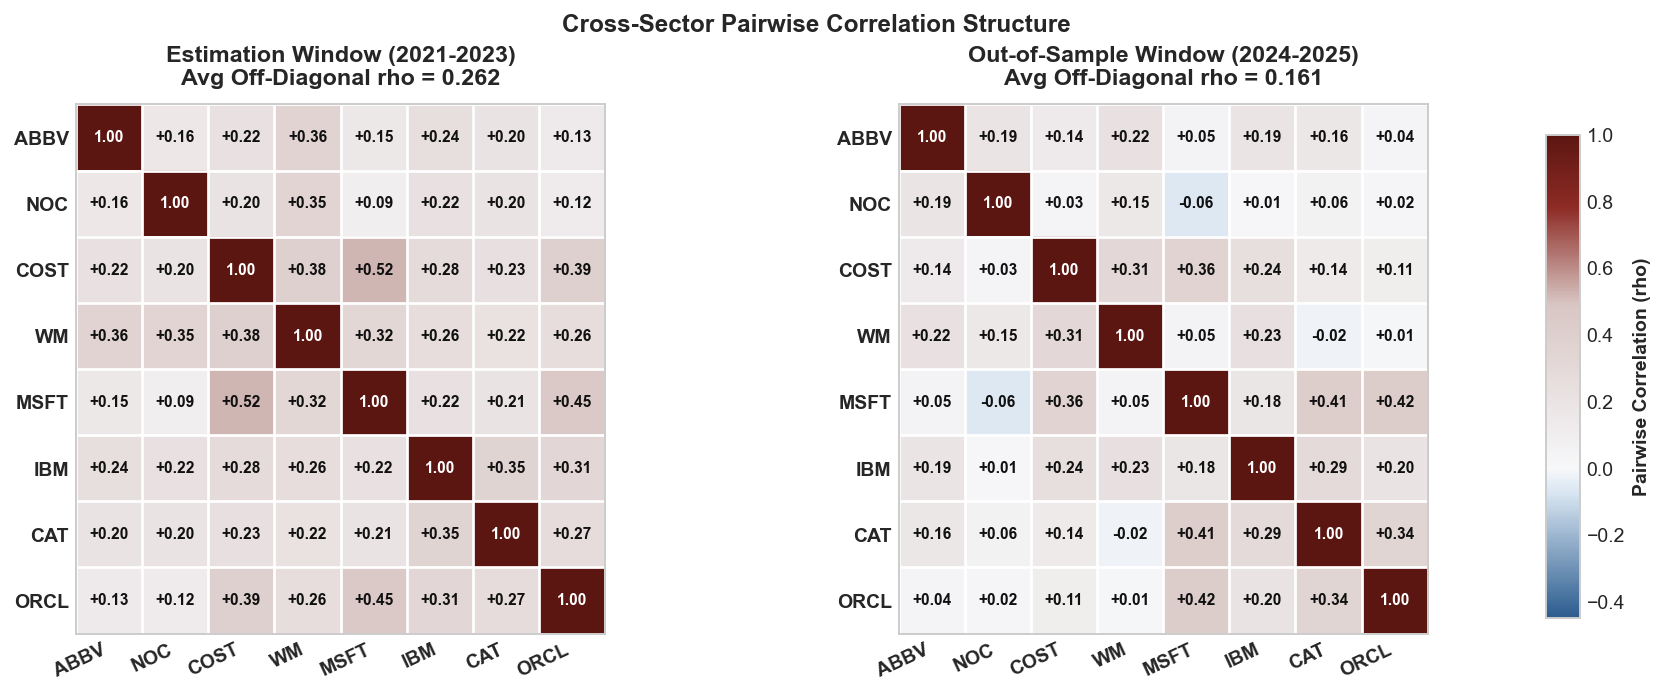

In [4]:
# 3. Draw estimation vs out-of-sample correlation heatmaps (centered at 0.0)
from matplotlib.colors import LinearSegmentedColormap
corr_cmap = LinearSegmentedColormap.from_list(
    'inst_div',
    [(0.0, '#2B5C8F'), (0.26, '#D9E6F2'), (0.31, '#F7F8FA'), (0.65, '#D8C6C3'), (0.85, '#8E2B25'), (1.0, '#5C1612')],
)
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4))
fig.subplots_adjust(left=0.06, right=0.87, top=0.84, bottom=0.14, wspace=0.22)
for ax, mat, ttl in [
    (axes[0], corr_tr, f'Estimation Window ({START_DATE[:4]}-{TRAIN_END[:4]})\nAvg Off-Diagonal rho = {cov_summary.loc[0, "Avg Rho (Train)"]:.3f}'),
    (axes[1], corr_te, f'Out-of-Sample Window ({test.index.min().year}-{END_DATE[:4]})\nAvg Off-Diagonal rho = {cov_summary.loc[0, "Avg Rho (Test)"]:.3f}'),
]:
    arr = mat.to_numpy()
    im = ax.imshow(arr, vmin=-0.45, vmax=1.0, cmap=corr_cmap, aspect='equal')
    ax.set_xticks(range(k), SELECTED, rotation=25, ha='right', fontweight='bold')
    ax.set_yticks(range(k), SELECTED, fontweight='bold')
    ax.set_xticks(np.arange(-0.5, k, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, k, 1), minor=True)
    ax.grid(False)
    ax.grid(which='minor', color='#FFFFFF', linestyle='-', linewidth=1.4)
    ax.tick_params(which='minor', bottom=False, left=False)
    ax.set_title(ttl, pad=10)
    for i in range(k):
        for j in range(k):
            v = arr[i, j]
            tcol = '#FFFFFF' if (v >= 0.56 or v <= -0.18) else '#111111'
            lbl = f'{v:+.2f}' if i != j else '1.00'
            ax.text(j, i, lbl, ha='center', va='center', fontsize=8, color=tcol, fontweight='bold')
cbar_ax = fig.add_axes([0.895, 0.16, 0.018, 0.64])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('Pairwise Correlation (rho)', fontweight='bold')
fig.suptitle('Cross-Sector Pairwise Correlation Structure', fontsize=12.5, fontweight='bold', y=0.96)
plt.show()

## Min Variance (G), Max Sharpe (P), and Efficient Frontier

Solves long-only `G` and `P` (`w >= 0, sum(w) = 1`) and traces the efficient frontier dynamically.

In [5]:
# 1. Calculate G, P, and efficient frontier curve
def solve_gp_and_frontier(mu_v, cov_m, n_pts=80):
    m = len(mu_v)
    w0 = np.ones(m) / m
    bnds = [(0, 1)] * m
    eq1 = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
    wg = minimize(lambda w: w @ cov_m @ w, w0, method='SLSQP', bounds=bnds, constraints=eq1, options={'ftol': 1e-12, 'maxiter': 2000}).x
    wp = minimize(lambda w: -(w @ mu_v - rf) / np.sqrt(w @ cov_m @ w), w0, method='SLSQP', bounds=bnds, constraints=eq1, options={'ftol': 1e-12, 'maxiter': 2000}).x
    gm = float(wg @ mu_v)
    lo, hi = float(mu_v.min()), float(mu_v.max())
    f_pts = []
    for tgt in np.linspace(lo, hi, n_pts):
        cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}, {'type': 'eq', 'fun': lambda w, t=tgt: w @ mu_v - t}]
        res = minimize(lambda w: w @ cov_m @ w, w0, method='SLSQP', bounds=bnds, constraints=cons, options={'ftol': 1e-11, 'maxiter': 1000})
        if res.success:
            w = res.x; mv = float(w @ mu_v); sv = float(np.sqrt(max(w @ cov_m @ w, 0)))
            f_pts.append({'Mean': mv, 'SD': sv, 'Efficient': mv >= gm - 1e-6})
    return wg, wp, pd.DataFrame(f_pts)

wG, wP, f_sel = solve_gp_and_frontier(mu_s, cov_s)  # Solve Min Variance G, Max Sharpe P, and efficient frontier
g_m, g_s = float(wG @ mu_s), float(np.sqrt(wG @ cov_s @ wG))  # Compute Global Min Variance G expected return and SD
p_m, p_v, p_s = float(wP @ mu_s), float(wP @ cov_s @ wP), float(np.sqrt(wP @ cov_s @ wP))  # Compute Optimal Risky P expected return, variance, and SD

wG4, wP4, f4 = solve_gp_and_frontier(mu4, cov4)  # Solve comparison 4-stock G, P, and frontier
g4_m, g4_s = float(wG4 @ mu4), float(np.sqrt(wG4 @ cov4 @ wG4))
p4_m, p4_v, p4_s = float(wP4 @ mu4), float(wP4 @ cov4 @ wP4), float(np.sqrt(wP4 @ cov4 @ wP4))

In [6]:
# 2. Output G and P weights and summary metrics
gp_tbl = pd.DataFrame({'Sector': [SECTORS.get(t, 'US Equity') for t in SELECTED], 'Mean': mu_s, 'SD': np.sqrt(np.diag(cov_s)), 'G Weight': wG, 'P Weight': wP}, index=SELECTED)
gp4_tbl = pd.DataFrame({'Sector': [SECTORS.get(t, 'US Equity') for t in TOP4], 'Mean': mu4, 'SD': np.sqrt(np.diag(cov4)), 'G Weight': wG4, 'P Weight': wP4}, index=TOP4)
gp_sum = pd.DataFrame([
    {'Portfolio': f'{k}-Stock G', 'Mean': g_m, 'SD': g_s, 'Sharpe': (g_m - rf) / g_s, 'Cutoff A': np.nan},
    {'Portfolio': f'{k}-Stock P', 'Mean': p_m, 'SD': p_s, 'Sharpe': (p_m - rf) / p_s, 'Cutoff A': (p_m - rf) / p_v},
    {'Portfolio': f'Top-{k4} G', 'Mean': g4_m, 'SD': g4_s, 'Sharpe': (g4_m - rf) / g4_s, 'Cutoff A': np.nan},
    {'Portfolio': f'Top-{k4} P', 'Mean': p4_m, 'SD': p4_s, 'Sharpe': (p4_m - rf) / p4_s, 'Cutoff A': (p4_m - rf) / p4_v},
])
display(gp_sum); display(gp_tbl); display(gp4_tbl)  # Display formatted summary table

,Portfolio,Mean,SD,Sharpe,Cutoff A
0,8-Stock G,0.19608,0.13533,1.12820,NaN
1,8-Stock P,0.20556,0.13947,1.16270,8.33649
2,Top-4 G,0.19725,0.15005,1.02533,NaN
3,Top-4 P,0.20382,0.15322,1.04702,6.83344


,Sector,Mean,SD,G Weight,P Weight
ABBV,Pharmaceuticals,0.19257,0.20711,0.22925,0.23023
NOC,Defense,0.20246,0.24975,0.13162,0.15876
COST,Warehouse retail,0.22854,0.23902,0.06414,0.13342
WM,Waste services,0.18222,0.18221,0.24670,0.12915
MSFT,Software,0.23077,0.27835,0.06148,0.09599
IBM,IT services,0.17942,0.21120,0.19239,0.09574
CAT,Construction equipment,0.22692,0.29405,0.04379,0.09329
ORCL,Enterprise software,0.22957,0.29983,0.03064,0.06343


,Sector,Mean,SD,G Weight,P Weight
COST,Warehouse retail,0.22854,0.23902,0.14775,0.23647
WM,Waste services,0.18222,0.18221,0.42008,0.28649
ABBV,Pharmaceuticals,0.19257,0.20711,0.33508,0.32751
MSFT,Software,0.23077,0.27835,0.09709,0.14953


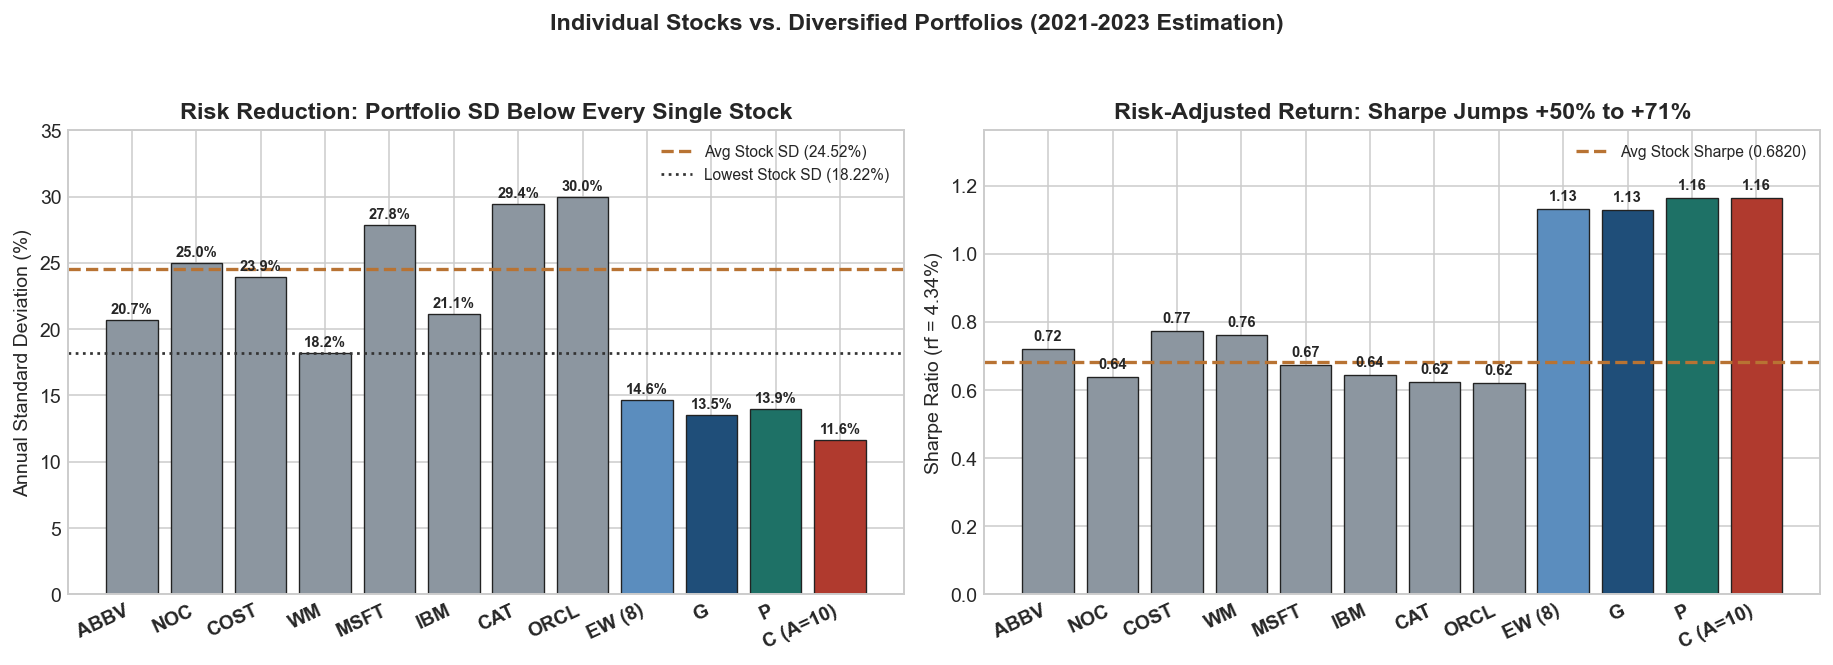

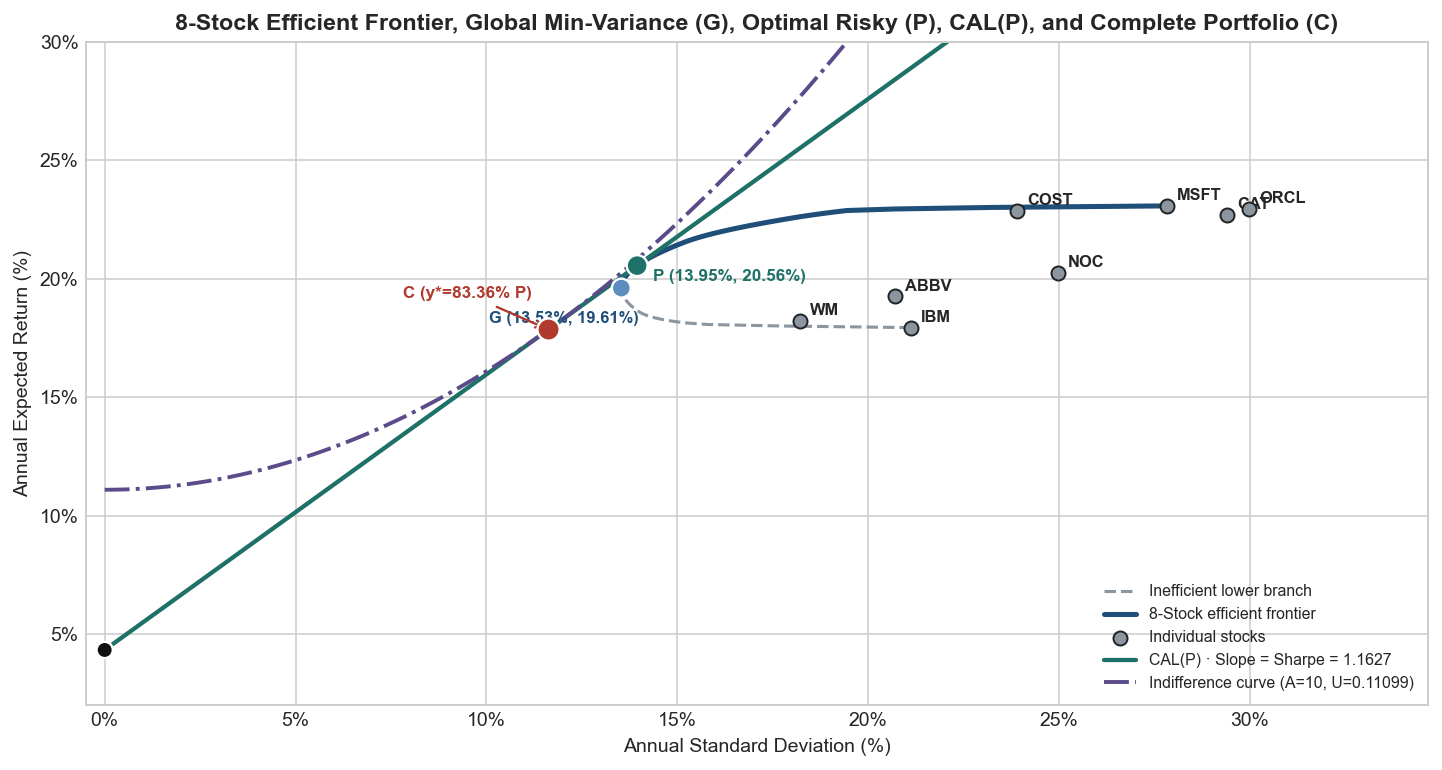

In [7]:
# 3. Draw Individual vs Diversified Portfolios (Figure 1) and Efficient Frontier (Figure 3)
ann_sd_s = np.sqrt(np.diag(cov_s))
indiv_sr_s = (mu_s - rf) / ann_sd_s
y_tmp = float(np.clip((p_m - rf) / (A * p_v), 0.0, 1.0))  # Optimal risky share at A
c_m_tmp = rf + y_tmp * (p_m - rf); c_s_tmp = y_tmp * p_s; c_u_tmp = c_m_tmp - 0.5 * A * (c_s_tmp ** 2)
ew_m_tmp = float((np.ones(k) / k) @ mu_s); ew_s_tmp = float(np.sqrt(ew_var))
labels_f1 = list(SELECTED) + [f'EW ({k})', 'G', 'P', f'C (A={A:g})']
sds_f1 = np.r_[ann_sd_s, ew_s_tmp, g_s, p_s, c_s_tmp] * 100
srs_f1 = np.r_[indiv_sr_s, (ew_m_tmp - rf)/ew_s_tmp, (g_m - rf)/g_s, (p_m - rf)/p_s, (c_m_tmp - rf)/c_s_tmp]
bar_c = [COL_SLATE]*k + [COL_STEEL, COL_NAVY, COL_TEAL, COL_CRIMSON]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8))  # Create side-by-side two-panel figure
fig.patch.set_facecolor('#FFFFFF')
x1 = np.arange(len(labels_f1))
b1 = ax1.bar(x1, sds_f1, color=bar_c, edgecolor='#222222', lw=0.7)
ax1.axhline(ann_sd_s.mean()*100, color=COL_AMBER, linestyle='--', lw=1.7, label=f'Avg Stock SD ({ann_sd_s.mean():.2%})')  # Reference line for average standalone stock volatility
ax1.axhline(ann_sd_s.min()*100, color='#333333', linestyle=':', lw=1.4, label=f'Lowest Stock SD ({ann_sd_s.min():.2%})')  # Reference line for average standalone stock volatility
for r_b, v in zip(b1, sds_f1): ax1.text(r_b.get_x()+r_b.get_width()/2, v+0.5, f'{v:.1f}%', ha='center', fontsize=7.6, fontweight='bold')
ax1.set_xticks(x1, labels_f1, rotation=25, ha='right', fontweight='bold')
ax1.set(ylim=(0, max(35, sds_f1.max()+5)), ylabel='Annual Standard Deviation (%)', title='Risk Reduction: Portfolio SD Below Every Single Stock')  # Configure left/top panel labels and title
ax1.legend(fontsize=8.0)

b2 = ax2.bar(x1, srs_f1, color=bar_c, edgecolor='#222222', lw=0.7)
ax2.axhline(indiv_sr_s.mean(), color=COL_AMBER, linestyle='--', lw=1.7, label=f'Avg Stock Sharpe ({indiv_sr_s.mean():.4f})')
for r_b, v in zip(b2, srs_f1): ax2.text(r_b.get_x()+r_b.get_width()/2, v+0.025, f'{v:.2f}', ha='center', fontsize=7.6, fontweight='bold')
ax2.set_xticks(x1, labels_f1, rotation=25, ha='right', fontweight='bold')
ax2.set(ylim=(0, max(1.35, srs_f1.max()+0.2)), ylabel=f'Sharpe Ratio (rf = {rf:.2%})', title='Risk-Adjusted Return: Sharpe Jumps +50% to +71%')  # Configure right/bottom panel labels and title
ax2.legend(fontsize=8.0)
fig.suptitle('Individual Stocks vs. Diversified Portfolios (2021-2023 Estimation)', fontsize=12.0, fontweight='bold', y=0.98)  # Add figure-wide title
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()  # Adjust spacing and render chart

# Paper Figure 3: Efficient Frontier, G, P, CAL(P), and Complete Portfolio C
fig, ax = plt.subplots(figsize=(10.4, 5.6))  # Create main figure canvas
fig.patch.set_facecolor('#FFFFFF')
ineff = f_sel[~f_sel['Efficient']]; eff = f_sel[f_sel['Efficient']]  # Split frontier into lower inefficient branch and upper efficient frontier
ax.plot(ineff['SD']*100, ineff['Mean']*100, '--', color=COL_SLATE, lw=1.6, label='Inefficient lower branch')
ax.plot(eff['SD']*100, eff['Mean']*100, '-', color=COL_NAVY, lw=2.6, label=f'{k}-Stock efficient frontier')  # Plot long-only Markowitz efficient frontier
ax.scatter(ann_sd_s*100, mu_s*100, color=COL_SLATE, edgecolor='#222222', s=52, zorder=4, label='Individual stocks')  # Plot individual stocks in risk-return space
for i, t in enumerate(SELECTED):
    ax.annotate(t, (ann_sd_s[i]*100, mu_s[i]*100), xytext=(5, 3), textcoords='offset points', fontsize=8.4, fontweight='bold')
sig = np.linspace(0, max(0.31, float(ann_sd_s.max())+0.04), 250)
p_sr_tmp = (p_m - rf) / p_s
ax.plot(sig*100, (rf + p_sr_tmp*sig)*100, color=COL_TEAL, lw=2.2, label=f'CAL(P) · Slope = Sharpe = {p_sr_tmp:.4f}')  # Plot Capital Allocation Line CAL(P) from T-bills through P
ax.plot(sig*100, (c_u_tmp + 0.5*A*sig**2)*100, '-.', color=COL_PLUM, lw=2.0, label=f'Indifference curve (A={A:g}, U={c_u_tmp:.5f})')  # Plot quadratic utility indifference curve tangent at Complete Portfolio C
ax.scatter([0, g_s*100, p_s*100, c_s_tmp*100], [rf*100, g_m*100, p_m*100, c_m_tmp*100],  # Highlight key portfolios: T-bills (F), Min Variance (G), Max Sharpe (P), and Complete (C)
           color=['#111111', COL_STEEL, COL_TEAL, COL_CRIMSON], edgecolor='#FFFFFF', lw=1.2, s=[70, 95, 115, 130], zorder=6)
ax.annotate(f'G ({g_s:.2%}, {g_m:.2%})', (g_s*100, g_m*100), xytext=(-68, -18), textcoords='offset points', fontsize=8.5, fontweight='bold', color=COL_NAVY)
ax.annotate(f'P ({p_s:.2%}, {p_m:.2%})', (p_s*100, p_m*100), xytext=(8, -8), textcoords='offset points', fontsize=8.8, fontweight='bold', color=COL_TEAL)
ax.annotate(f'C (y*={y_tmp:.2%} P)', (c_s_tmp*100, c_m_tmp*100), xytext=(-75, 16), textcoords='offset points', arrowprops=dict(arrowstyle='->', color=COL_CRIMSON, lw=1.2), fontsize=8.8, fontweight='bold', color=COL_CRIMSON)
ax.set(xlim=(-0.5, sig.max()*102), ylim=(2, max(30, mu_s.max()*125)), xlabel='Annual Standard Deviation (%)', ylabel='Annual Expected Return (%)',  # Configure axis labels, limits, and title
       title=f'{k}-Stock Efficient Frontier, Global Min-Variance (G), Optimal Risky (P), CAL(P), and Complete Portfolio (C)')
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.legend(fontsize=8.2, loc='lower right'); plt.tight_layout(); plt.show()

## Complete Portfolio C & Separation Property

Combines the accepted risky portfolio `P` with 3-Month T-Bills at your chosen `A` and `rf`, and sweeps risk aversion `A` to illustrate the Separation Property.

In [8]:
# 1. Calculate Complete Portfolio C and Separation Property sweep
y_sel = float(np.clip((p_m - rf) / (A * p_v), 0.0, 1.0))  # Optimal risky share y* capped at [0%, 100%] (no borrowing)
t_sel = 1.0 - y_sel  # Remaining allocation held in risk-free 3-month T-bills
c_m = rf + y_sel * (p_m - rf); c_s = y_sel * p_s; c_u = c_m - 0.5 * A * c_s ** 2  # Complete Portfolio C return, SD, and quadratic utility
cutoff_A = (p_m - rf) / p_v  # Implied risk aversion A where unconstrained y* equals 100%

y4 = float(np.clip((p4_m - rf) / (A_COMP * p4_v), 0.0, 1.0))
t4 = 1.0 - y4
c4_m = rf + y4 * (p4_m - rf); c4_s = y4 * p4_s; c4_u = c4_m - 0.5 * A_COMP * c4_s ** 2

def sweep_A(a_list, pm, pv, ps):
    rows = []
    for av in a_list:
        yr = (pm - rf) / (av * pv)
        ya = float(np.clip(yr, 0.0, 1.0))
        mc = rf + ya * (pm - rf); sc = ya * ps
        rows.append({'A': av, 'Raw y*': yr, 'Applied y (P)': ya, 'T-bill Share': 1.0 - ya,
                     'Mean': mc, 'SD': sc, 'Sharpe': (mc - rf) / sc if sc > 0 else 0.0, 'Utility': mc - 0.5 * av * sc ** 2})
    return pd.DataFrame(rows)

sep_df = sweep_A(sorted(set([6.0, 7.5, round(cutoff_A, 3), 9.0, A, 11.0, 12.0, 14.0])), p_m, p_v, p_s)

In [9]:
# 2. Output Complete Portfolio C weights and Separation Property table
c_comp = pd.DataFrame([
    {'Portfolio': f'{k}-Stock C (A={A:g})', 'y* in P': y_sel, 'T-bill Share': t_sel, 'Mean': c_m, 'SD': c_s, 'Sharpe': (c_m - rf) / c_s if c_s > 0 else 0.0, 'Utility': c_u},
    {'Portfolio': f'Top-{k4} C (A={A_COMP:g})', 'y* in P': y4, 'T-bill Share': t4, 'Mean': c4_m, 'SD': c4_s, 'Sharpe': (c4_m - rf) / c4_s if c4_s > 0 else 0.0, 'Utility': c4_u},
])
c_weights = pd.DataFrame({
    'Weight in P': np.r_[wP, 0.0],
    'Weight in C': np.r_[y_sel * wP, t_sel],
    f'USD per ${MONTHLY_USD:g}': np.r_[y_sel * wP, t_sel] * MONTHLY_USD,
}, index=SELECTED + ['US 3M T-Bills'])
display(c_comp); display(c_weights); display(sep_df)  # Display formatted summary table

,Portfolio,y* in P,T-bill Share,Mean,SD,Sharpe,Utility
0,8-Stock C (A=10),0.83365,0.16635,0.17859,0.11627,1.16270,0.11099
1,Top-4 C (A=6),1.00000,0.00000,0.20382,0.15322,1.04702,0.13339


,Weight in P,Weight in C,USD per $100
ABBV,0.23023,0.19193,19.19299
NOC,0.15876,0.13235,13.23522
COST,0.13342,0.11122,11.12237
WM,0.12915,0.10766,10.76627
MSFT,0.09599,0.08002,8.00210
IBM,0.09574,0.07981,7.98098
CAT,0.09329,0.07777,7.77713
ORCL,0.06343,0.05288,5.28786
US 3M T-Bills,0.00000,0.16635,16.63507


,A,Raw y*,Applied y (P),T-bill Share,Mean,SD,Sharpe,Utility
0,6.00000,1.38942,1.00000,0.00000,0.20556,0.13947,1.16270,0.14721
1,7.50000,1.11153,1.00000,0.00000,0.20556,0.13947,1.16270,0.13262
2,8.33600,1.00006,1.00000,0.00000,0.20556,0.13947,1.16270,0.12449
3,9.00000,0.92628,0.92628,0.07372,0.19361,0.12919,1.16270,0.11850
4,10.00000,0.83365,0.83365,0.16635,0.17859,0.11627,1.16270,0.11099
5,11.00000,0.75786,0.75786,0.24214,0.16630,0.10570,1.16270,0.10485
6,12.00000,0.69471,0.69471,0.30529,0.15606,0.09689,1.16270,0.09973
7,14.00000,0.59546,0.59546,0.40454,0.13996,0.08305,1.16270,0.09168


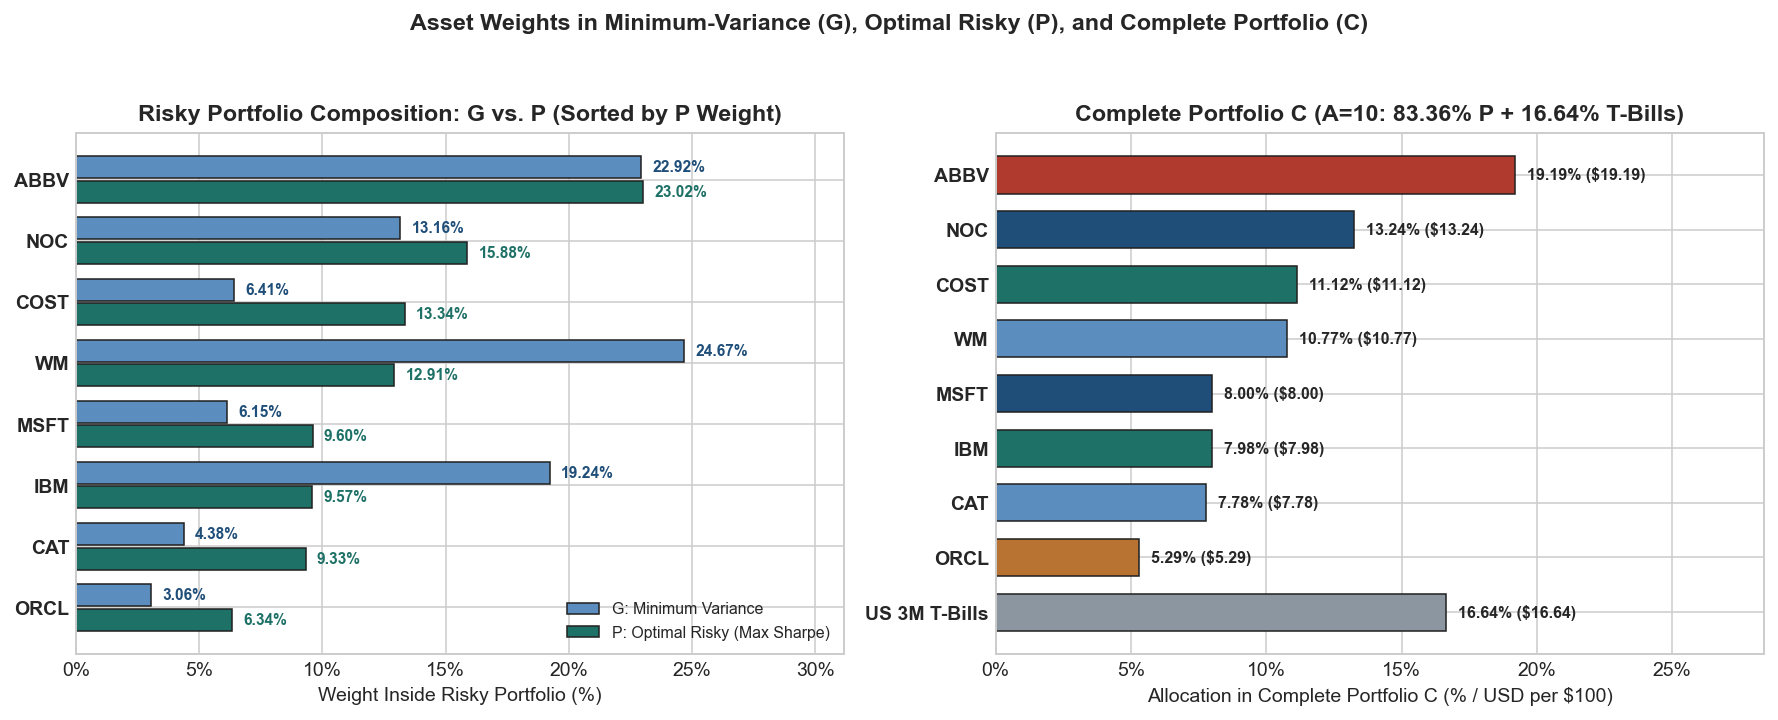

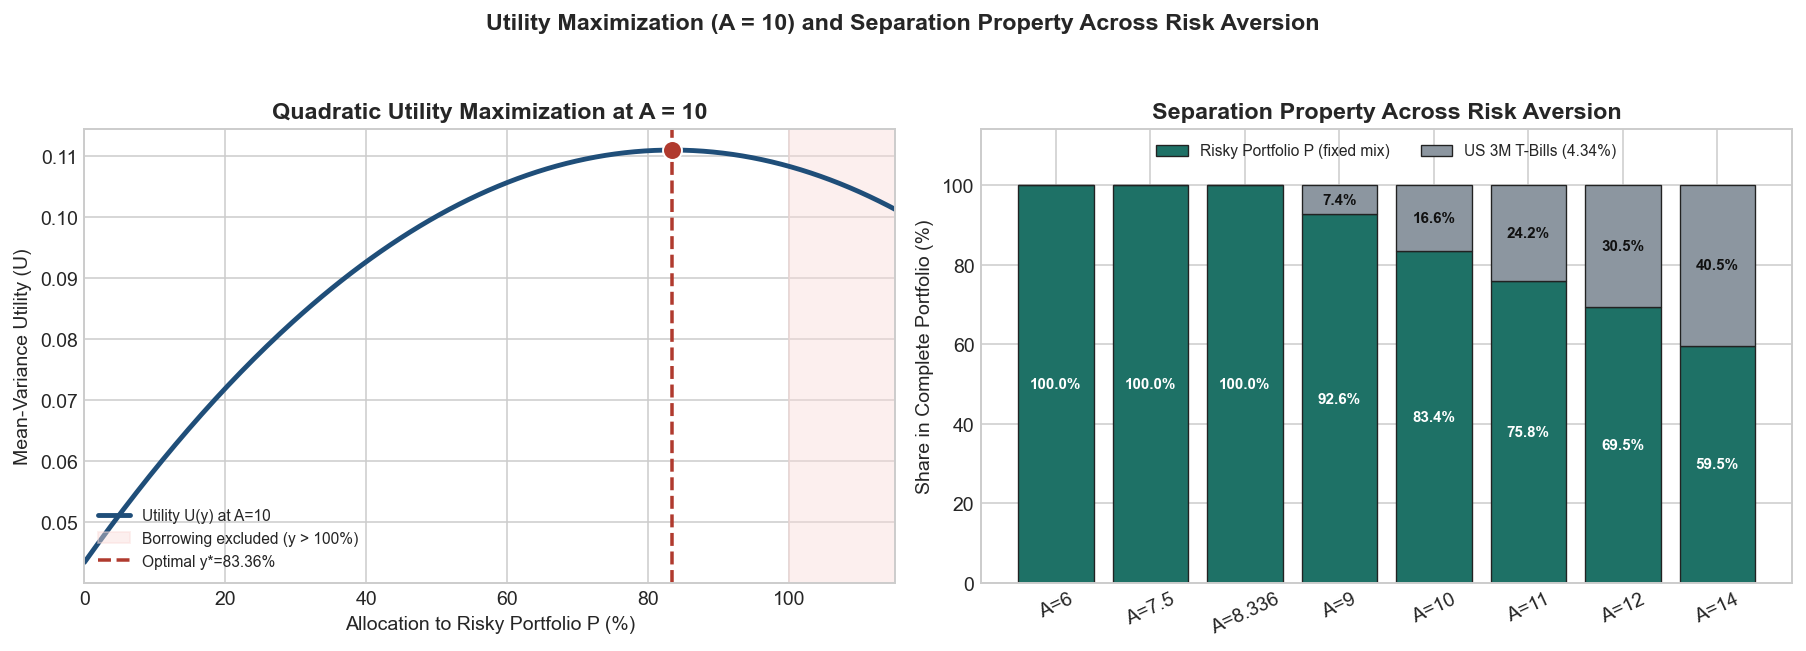

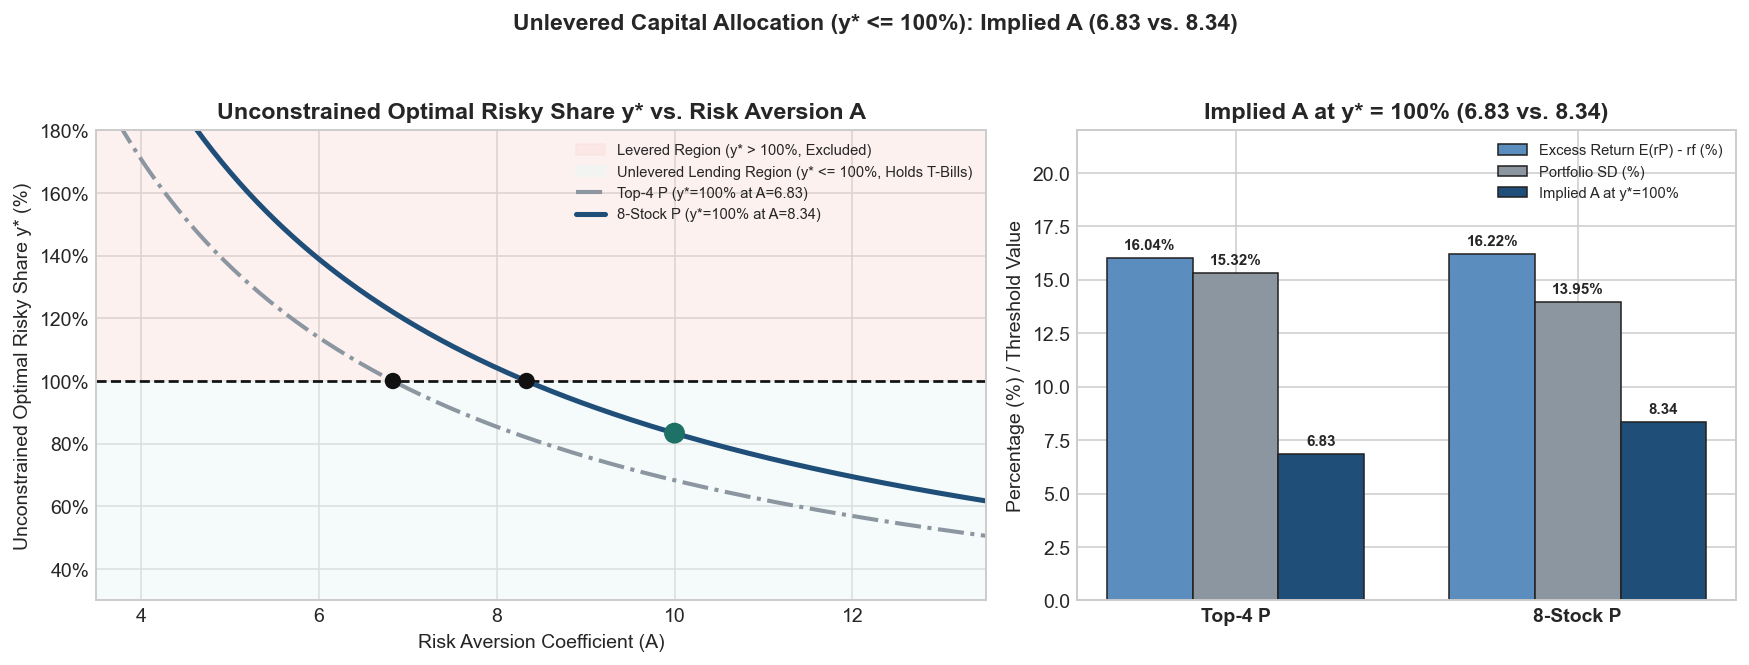

In [10]:
# 3. Draw Asset Weights (Figure 4), Utility & Separation (Figure 5), and Unlevered Boundary (Figure 5B)
gpw = pd.DataFrame({'Ticker': SELECTED, 'G Weight': wG, 'P Weight': wP}).sort_values('P Weight', ascending=False).iloc[::-1].reset_index(drop=True)
y_gp = np.arange(len(gpw)); bh = 0.36
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 5.2))  # Create side-by-side two-panel figure
fig.patch.set_facecolor('#FFFFFF')
b1 = ax1.barh(y_gp + bh/2 + 0.02, gpw['G Weight']*100, height=bh, color=COL_STEEL, edgecolor='#222222', lw=0.8, label='G: Minimum Variance')  # Horizontal bars for Minimum Variance portfolio G weights
b2 = ax1.barh(y_gp - bh/2 - 0.02, gpw['P Weight']*100, height=bh, color=COL_TEAL, edgecolor='#222222', lw=0.8, label='P: Optimal Risky (Max Sharpe)')  # Horizontal bars for Maximum Sharpe portfolio P weights
for r_b in b1: ax1.text(r_b.get_width()+0.45, r_b.get_y()+r_b.get_height()/2, f'{r_b.get_width():.2f}%', va='center', fontsize=8.0, fontweight='bold', color=COL_NAVY)
for r_b in b2: ax1.text(r_b.get_width()+0.45, r_b.get_y()+r_b.get_height()/2, f'{r_b.get_width():.2f}%', va='center', fontsize=8.0, fontweight='bold', color=COL_TEAL)
ax1.set_yticks(y_gp, gpw['Ticker'], fontweight='bold'); ax1.set_xlim(0, max(gpw['G Weight'].max(), gpw['P Weight'].max())*100 + 6.5)
ax1.xaxis.set_major_formatter(PercentFormatter(decimals=0)); ax1.set(xlabel='Weight Inside Risky Portfolio (%)', title='Risky Portfolio Composition: G vs. P (Sorted by P Weight)'); ax1.legend(loc='lower right', fontsize=8.2)

c_lbls = ['US 3M T-Bills'] + gpw['Ticker'].tolist()
c_vals = [t_sel*100] + (gpw['P Weight'].to_numpy()*y_sel*100).tolist()
base_pal = [COL_CRIMSON, COL_NAVY, COL_TEAL, COL_STEEL, COL_NAVY, COL_TEAL, COL_STEEL, COL_AMBER]
c_cols = [COL_SLATE] + [base_pal[i % len(base_pal)] for i in range(len(gpw))][::-1]
hb = ax2.barh(np.arange(len(c_lbls)), c_vals, height=0.68, color=c_cols, edgecolor='#222222', lw=0.8)  # Horizontal bars for Complete Portfolio C weights including 3-month T-bills
for r_b, val in zip(hb, c_vals): ax2.text(val+0.45, r_b.get_y()+r_b.get_height()/2, f'{val:.2f}% (${val:.2f})', va='center', fontsize=8.2, fontweight='bold')
ax2.set_yticks(np.arange(len(c_lbls)), c_lbls, fontweight='bold'); ax2.set_xlim(0, max(c_vals)+9.2)
ax2.xaxis.set_major_formatter(PercentFormatter(decimals=0)); ax2.set(xlabel='Allocation in Complete Portfolio C (% / USD per $100)', title=f'Complete Portfolio C (A={A:g}: {y_sel*100:.2f}% P + {t_sel*100:.2f}% T-Bills)')
fig.suptitle('Asset Weights in Minimum-Variance (G), Optimal Risky (P), and Complete Portfolio (C)', fontsize=12.0, fontweight='bold', y=0.98)  # Add figure-wide title
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()  # Adjust spacing and render chart

# Paper Figure 5: Utility Maximization & Separation Property
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 4.7))  # Create side-by-side two-panel figure
fig.patch.set_facecolor('#FFFFFF')
yg = np.linspace(0, 1.15, 250); ug = rf + yg*(p_m - rf) - 0.5*A*(yg*p_s)**2  # Evaluate quadratic utility U(y) across risky allocation y from 0% to 115%
ax1.plot(yg*100, ug, color=COL_NAVY, lw=2.5, label=f'Utility U(y) at A={A:g}')  # Plot mean-variance utility curve U(y)
ax1.axvspan(100, 115, color='#FADBD8', alpha=0.42, label='Borrowing excluded (y > 100%)')  # Shade levered region (y > 100%) excluded by no-borrowing policy
ax1.axvline(y_sel*100, color=COL_CRIMSON, linestyle='--', lw=1.8, label=f'Optimal y*={y_sel:.2%}')  # Mark optimal interior allocation y* where dU/dy = 0
ax1.scatter([y_sel*100], [c_u], color=COL_CRIMSON, edgecolor='#FFFFFF', s=95, zorder=6)
ax1.set(xlim=(0, 115), xlabel='Allocation to Risky Portfolio P (%)', ylabel='Mean-Variance Utility (U)', title=f'Quadratic Utility Maximization at A = {A:g}'); ax1.legend(fontsize=8, loc='lower left')  # Configure left/top panel labels and title
xp = np.arange(len(sep_df)); pp = sep_df['Applied y (P)'].to_numpy()*100; tp = sep_df['T-bill Share'].to_numpy()*100
ax2.bar(xp, pp, color=COL_TEAL, edgecolor='#222222', lw=0.7, label='Risky Portfolio P (fixed mix)')  # Stacked bar: fixed risky portfolio P share across A
ax2.bar(xp, tp, bottom=pp, color=COL_SLATE, edgecolor='#222222', lw=0.7, label=f'US 3M T-Bills ({rf:.2%})')  # Stacked bar: risk-free 3-month T-bill share across A
for i, (pv_i, tv_i) in enumerate(zip(pp, tp)):
    ax2.text(i, pv_i/2, f'{pv_i:.1f}%', ha='center', va='center', color='white', fontsize=7.8, fontweight='bold')
    if tv_i > 6: ax2.text(i, pv_i+tv_i/2, f'{tv_i:.1f}%', ha='center', va='center', color='#111111', fontsize=7.8, fontweight='bold')
ax2.set_xticks(xp, [f'A={v:g}' for v in sep_df['A']], rotation=25); ax2.set(ylim=(0, 114), ylabel='Share in Complete Portfolio (%)', title='Separation Property Across Risk Aversion'); ax2.legend(fontsize=8, loc='upper center', ncol=2)
fig.suptitle(f'Utility Maximization (A = {A:g}) and Separation Property Across Risk Aversion', fontsize=12.0, fontweight='bold', y=0.98)  # Add figure-wide title
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()  # Adjust spacing and render chart

# Paper Figure 5B: Unlevered Capital Allocation Boundary (y* <= 100%)
ex4, ex_s = p4_m - rf, p_m - rf; ab4, ab_s = ex4 / p4_v, ex_s / p_v  # Compute risk premiums and implied y*=100% boundary A for both portfolios
Ag = np.linspace(3.5, 13.5, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.8), gridspec_kw={'width_ratios': [1.35, 1.0]})  # Create side-by-side two-panel figure
fig.patch.set_facecolor('#FFFFFF')
ax1.axhspan(100, 185, color='#FADBD8', alpha=0.38, label='Levered Region (y* > 100%, Excluded)')  # Shade levered region (y* > 100%) not allowed without borrowing
ax1.axhspan(0, 100, color='#E8F8F5', alpha=0.45, label='Unlevered Lending Region (y* <= 100%, Holds T-Bills)')  # Shade unlevered lending region where T-bills enter Complete Portfolio C
ax1.axhline(100, color='#111111', linestyle='--', lw=1.4)
ax1.plot(Ag, (ab4/Ag)*100, color=COL_SLATE, linestyle='-.', lw=2.1, label=f'Top-{k4} P (y*=100% at A={ab4:.2f})')  # Plot unconstrained y* vs A for 4-stock comparison portfolio
ax1.plot(Ag, (ab_s/Ag)*100, color=COL_NAVY, lw=2.6, label=f'{k}-Stock P (y*=100% at A={ab_s:.2f})')  # Plot unconstrained y* vs A for active Markowitz portfolio P
ax1.scatter([ab4, ab_s, A], [100, 100, y_sel*100], color=['#111111', '#111111', COL_TEAL], s=[55, 55, 95], zorder=6)
ax1.set(xlim=(3.5, 13.5), ylim=(30, 180), xlabel='Risk Aversion Coefficient (A)', ylabel='Unconstrained Optimal Risky Share y* (%)', title='Unconstrained Optimal Risky Share y* vs. Risk Aversion A')  # Configure left/top panel labels and title
ax1.yaxis.set_major_formatter(PercentFormatter(decimals=0)); ax1.legend(fontsize=7.6)
xc = np.arange(2); bw = 0.25
b_ex = ax2.bar(xc-bw, [ex4*100, ex_s*100], width=bw, color=COL_STEEL, edgecolor='#222222', lw=0.8, label='Excess Return E(rP) - rf (%)')
b_sd = ax2.bar(xc, [p4_s*100, p_s*100], width=bw, color=COL_SLATE, edgecolor='#222222', lw=0.8, label='Portfolio SD (%)')
b_ab = ax2.bar(xc+bw, [ab4, ab_s], width=bw, color=COL_NAVY, edgecolor='#222222', lw=0.8, label='Implied A at y*=100%')
for r_b, txt in [(b_ex[0], f'{ex4*100:.2f}%'), (b_ex[1], f'{ex_s*100:.2f}%'), (b_sd[0], f'{p4_s*100:.2f}%'), (b_sd[1], f'{p_s*100:.2f}%'), (b_ab[0], f'{ab4:.2f}'), (b_ab[1], f'{ab_s:.2f}')]:
    ax2.text(r_b.get_x()+r_b.get_width()/2, r_b.get_height()+0.4, txt, ha='center', fontsize=7.8, fontweight='bold')
ax2.set_xticks(xc, [f'Top-{k4} P', f'{k}-Stock P'], fontweight='bold'); ax2.set(ylim=(0, 22), ylabel='Percentage (%) / Threshold Value', title=f'Implied A at y* = 100% ({ab4:.2f} vs. {ab_s:.2f})'); ax2.legend(fontsize=7.6)
fig.suptitle(f'Unlevered Capital Allocation (y* <= 100%): Implied A ({ab4:.2f} vs. {ab_s:.2f})', fontsize=11.8, fontweight='bold', y=0.98)  # Add figure-wide title
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()  # Adjust spacing and render chart